# Problem Solving Using Data: Lab 6 - Question 3

## How do we answer the question at the end of Chapter 1 with Matplotlib?

At the end of Chapter 1, we asked:

**Why does the probability of observing an extreme result decrease as the coin is flipped more times?**

To answer this visually, we will compare the probability distributions for:

- 10 coin flips
- 20 coin flips

We will then compare the probability of obtaining extreme head or tail frequencies.

## Setup

This notebook is self-contained, so we first import the required libraries and define the functions used in the analysis.

In [1]:
import matplotlib.pyplot as plt
import math

In [2]:
def is_in_interval(val, start, end):
    return start <= val <= end

## Creating a Function for Coin-Flip Sample Spaces

We will create a reusable function that generates the weighted sample space for any number of fair coin flips.

The dictionary keys represent possible head counts.

The values represent how many different coin-flip combinations produce each head count.

In [3]:
def generate_coin_sample_space(num_flips):
    return {
        k: math.comb(num_flips, k)
        for k in range(num_flips + 1)
    }

## Probability Distribution for 10 Coin Flips

We first generate the weighted sample space and probability distribution for 10 coin flips.

In [4]:
weighted_sample_space = generate_coin_sample_space(10)

x_10_flips = list(weighted_sample_space.keys())

y_10_flips = [
    weighted_sample_space[key]
    for key in x_10_flips
]

sample_space_size_10 = sum(
    weighted_sample_space.values()
)

prob_x_10_flips = [
    value / sample_space_size_10
    for value in y_10_flips
]

## Probability Distribution for 20 Coin Flips

Next, we repeat the same process for 20 coin flips.

In [5]:
weighted_sample_space_20_flips = generate_coin_sample_space(20)

x_20_flips = list(
    weighted_sample_space_20_flips.keys()
)

y_20_flips = [
    weighted_sample_space_20_flips[key]
    for key in x_20_flips
]

sample_space_size_20 = sum(
    weighted_sample_space_20_flips.values()
)

prob_x_20_flips = [
    value / sample_space_size_20
    for value in y_20_flips
]

## Comparing the Two Probability Distributions

We can now plot the 10-flip and 20-flip probability distributions on the same graph.

The 10-flip distribution is labeled A.

The 20-flip distribution is labeled B.

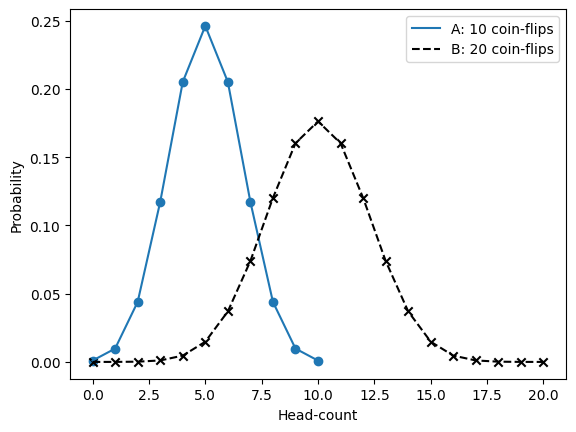

In [6]:
plt.plot(
    x_10_flips,
    prob_x_10_flips,
    label='A: 10 coin-flips'
)

plt.scatter(
    x_10_flips,
    prob_x_10_flips
)

plt.plot(
    x_20_flips,
    prob_x_20_flips,
    color='black',
    linestyle='--',
    label='B: 20 coin-flips'
)

plt.scatter(
    x_20_flips,
    prob_x_20_flips,
    color='k',
    marker='x'
)

plt.xlabel('Head-count')
plt.ylabel('Probability')

plt.legend()
plt.show()

Both distributions are centered around the expected result of 50% heads.

For 10 coin flips, the center occurs at 5 heads.

For 20 coin flips, the center occurs at 10 heads.

## Highlighting Extreme Outcomes

For 10 coin flips, an extreme result is:

- 8 or more heads
- 8 or more tails, which is equivalent to 2 or fewer heads

For 20 coin flips, the corresponding 80% extreme result is:

- 16 or more heads
- 16 or more tails, which is equivalent to 4 or fewer heads

We can shade these regions using `plt.fill_between()`.

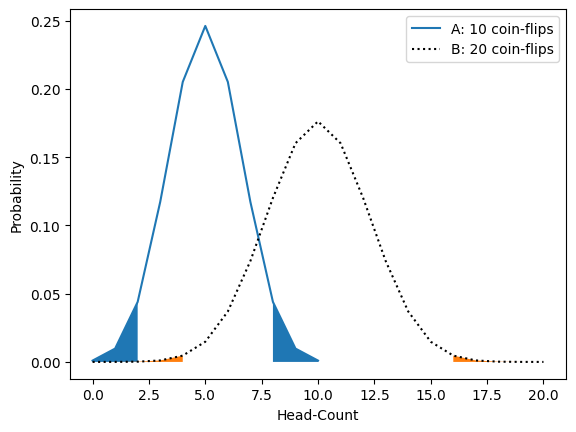

In [7]:
plt.plot(
    x_10_flips,
    prob_x_10_flips,
    label='A: 10 coin-flips'
)

plt.plot(
    x_20_flips,
    prob_x_20_flips,
    color='k',
    linestyle=':',
    label='B: 20 coin-flips'
)

where_10 = [
    not is_in_interval(value, 3, 7)
    for value in x_10_flips
]

plt.fill_between(
    x_10_flips,
    prob_x_10_flips,
    where=where_10
)

where_20 = [
    not is_in_interval(value, 5, 15)
    for value in x_20_flips
]

plt.fill_between(
    x_20_flips,
    prob_x_20_flips,
    where=where_20
)

plt.xlabel('Head-Count')
plt.ylabel('Probability')

plt.legend()
plt.show()

The shaded regions represent extreme results.

We can already see that the shaded tail regions for 20 coin flips are much smaller than the shaded regions for 10 coin flips.

This means that extreme outcomes are less probable when the coin is flipped more times.

## Converting Head Counts into Head Frequencies

Comparing 5 heads out of 10 flips with 10 heads out of 20 flips is easier if we convert the raw head counts into frequencies.

For example:

- 5 / 10 = 0.5
- 10 / 20 = 0.5

This allows both distributions to be centered at the same x-value of 0.5.

In [8]:
x_10_frequencies = [
    head_count / 10
    for head_count in x_10_flips
]

x_20_frequencies = [
    head_count / 20
    for head_count in x_20_flips
]

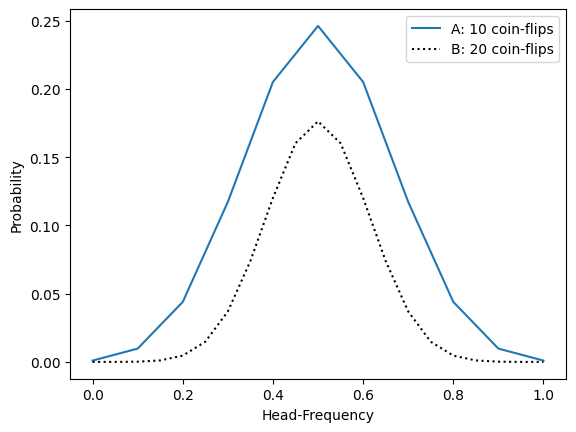

In [9]:
plt.plot(
    x_10_frequencies,
    prob_x_10_flips,
    label='A: 10 coin-flips'
)

plt.plot(
    x_20_frequencies,
    prob_x_20_flips,
    color='k',
    linestyle=':',
    label='B: 20 coin-flips'
)

plt.legend()

plt.xlabel('Head-Frequency')
plt.ylabel('Probability')

plt.show()

The centers of both distributions now line up at a head frequency of 0.5.

However, changing the spacing of the x-axis changes the area underneath each curve.

Because probability is represented by area, we need to adjust the y-values before directly comparing the distributions.

## Converting Probability into Relative Likelihood

For the 10-flip distribution, we multiply the probabilities by 10.

For the 20-flip distribution, we multiply the probabilities by 20.

This creates relative likelihood values while keeping the total area under each distribution equal to 1.

In [10]:
relative_likelihood_10 = [
    10 * prob
    for prob in prob_x_10_flips
]

relative_likelihood_20 = [
    20 * prob
    for prob in prob_x_20_flips
]

## Comparing the Aligned Distributions

Now we can plot both distributions using head frequency and relative likelihood.

We will also shade the extreme regions again.

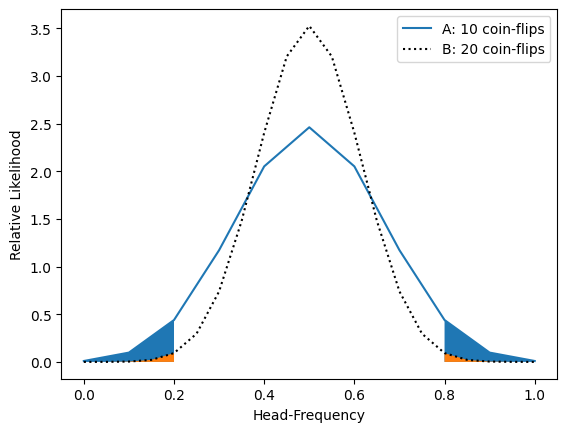

In [11]:
plt.plot(
    x_10_frequencies,
    relative_likelihood_10,
    label='A: 10 coin-flips'
)

plt.plot(
    x_20_frequencies,
    relative_likelihood_20,
    color='k',
    linestyle=':',
    label='B: 20 coin-flips'
)

plt.fill_between(
    x_10_frequencies,
    relative_likelihood_10,
    where=where_10
)

plt.fill_between(
    x_20_frequencies,
    relative_likelihood_20,
    where=where_20
)

plt.legend()

plt.xlabel('Head-Frequency')
plt.ylabel('Relative Likelihood')

plt.show()

The graph now makes the answer much easier to see.

The 10-flip distribution is shorter and wider.

The 20-flip distribution is taller and narrower around the expected head frequency of 0.5.

Because the 20-flip distribution is narrower, there is less area in the extreme regions near 0 and 1.

Since the area of those regions represents probability, extreme head frequencies become less likely as the number of coin flips increases.

## Answer to Question 3

We answer the question at the end of Chapter 1 by comparing the probability distributions for 10 coin flips and 20 coin flips.

When the number of coin flips increases, the distribution becomes taller and narrower around a head frequency of 0.5.

This means that results close to 50% heads become more likely, while extreme results such as 80% or more heads or tails become less likely.

The shaded extreme regions are much smaller for 20 flips than for 10 flips. Since the area under these regions represents probability, this shows why the probability of an extreme result decreases as the coin is flipped more times.

This connects to the **law of large numbers**: as the number of coin flips increases, the observed frequency of heads tends to get closer to the true probability of 0.5.